# How Cristiano Ronaldo's Scoring Rate Evolved Throughout His Career

Cristiano Ronaldo's goalscoring numbers are the focal point of his career, but they do not tell the whole story. Scoring rates help us examine the frequency at which he scored in while accounting for gaps in playing time. This brief analysis looks at Ronaldo's scoring rate in the following six ways:

1. Scoring rate by season (per match and per 90 minutes).
2. Games needed per 100-goal milestone.
3. Scoring output distribution.
4. Goal-scoring rate by competition.
5. Injury / absence hypothetical
6. Overall career goals time series.

In [18]:
# Setup

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data_dir = Path("../matches")
output_dir = Path("../../public/images/articles")
output_dir.mkdir(parents=True, exist_ok=True)

files = sorted(data_dir.glob("*.json"))
all_matches = []

for file in files:
    with open(file, "r", encoding="utf-8") as f:
        all_matches.extend(json.load(f))

matches_df = pd.DataFrame(all_matches)

matches_df["date"] = pd.to_datetime(
    matches_df["date"], errors="coerce"
)

for col in ["goals", "minutesPlayed"]:
    matches_df[col] = pd.to_numeric(
        matches_df[col], errors="coerce"
    )

matches_df = matches_df.dropna(
    subset=["date", "season", "goals"]
).copy()

matches_df = matches_df.sort_values("date").reset_index(drop=True)

season_order = (
    matches_df[["season", "date"]]
    .groupby("season")["date"]
    .min()
    .sort_values()
    .index
    .tolist()
)

matches_df["season"] = matches_df["season"].astype(str)

season_stats_all = (
    matches_df.groupby("season")
    .agg(
        appearances=("date", "size"),
        goals=("goals", "sum"),
        minutes=("minutesPlayed", "sum")
    )
    .reindex(season_order)
    .reset_index()
)

season_stats_all["goals_per_appearance"] = (
    season_stats_all["goals"] / season_stats_all["appearances"]
)

season_stats_all["goals_per_90"] = (
    season_stats_all["goals"] / season_stats_all["minutes"] * 90
)

print("Matches loaded:", len(matches_df))
print("Seasons found:", len(season_stats_all))

Matches loaded: 1340
Seasons found: 25


### Visualization 1: Scoring Rate By Season

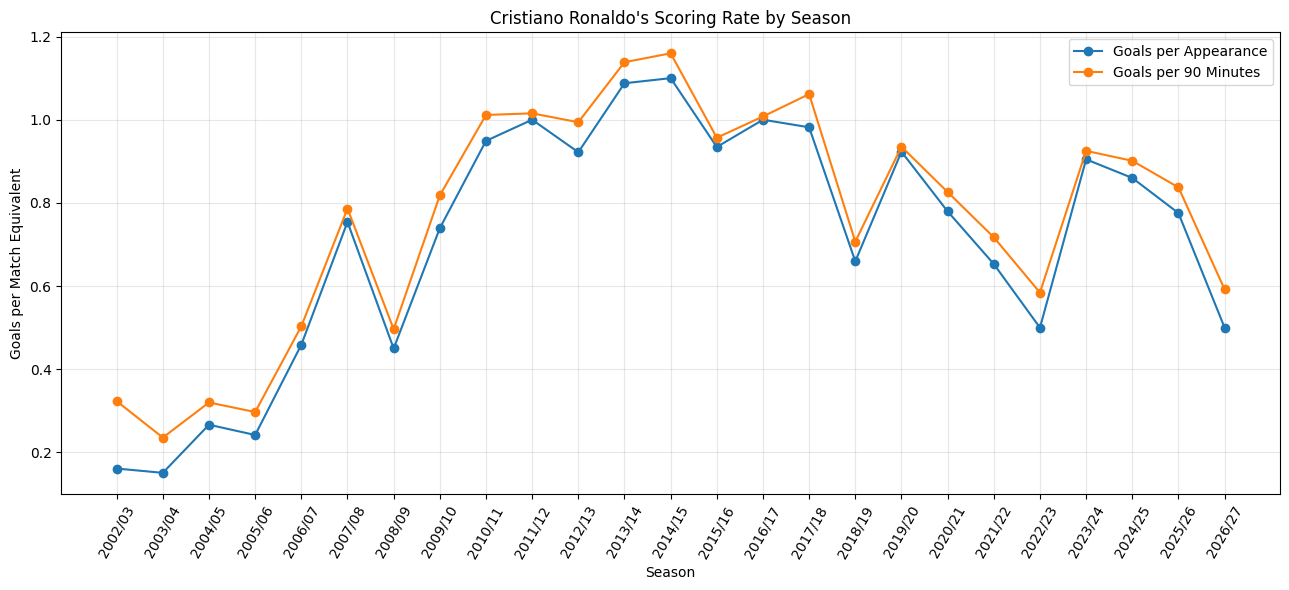

In [19]:
# Scoring Rate by Season (per match and per 90 minutes)

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    season_stats_all["season"],
    season_stats_all["goals_per_appearance"],
    marker="o",
    label="Goals per Appearance"
)

ax.plot(
    season_stats_all["season"],
    season_stats_all["goals_per_90"],
    marker="o",
    label="Goals per 90 Minutes"
)

ax.set_title("Cristiano Ronaldo's Scoring Rate by Season")
ax.set_xlabel("Season")
ax.set_ylabel("Goals per Match Equivalent")
ax.tick_params(axis="x", rotation=60)
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    output_dir / "ronaldo-scoring-rate-by-season.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

### Visualization 2: Games Needed for Each 100-Goal Milestone

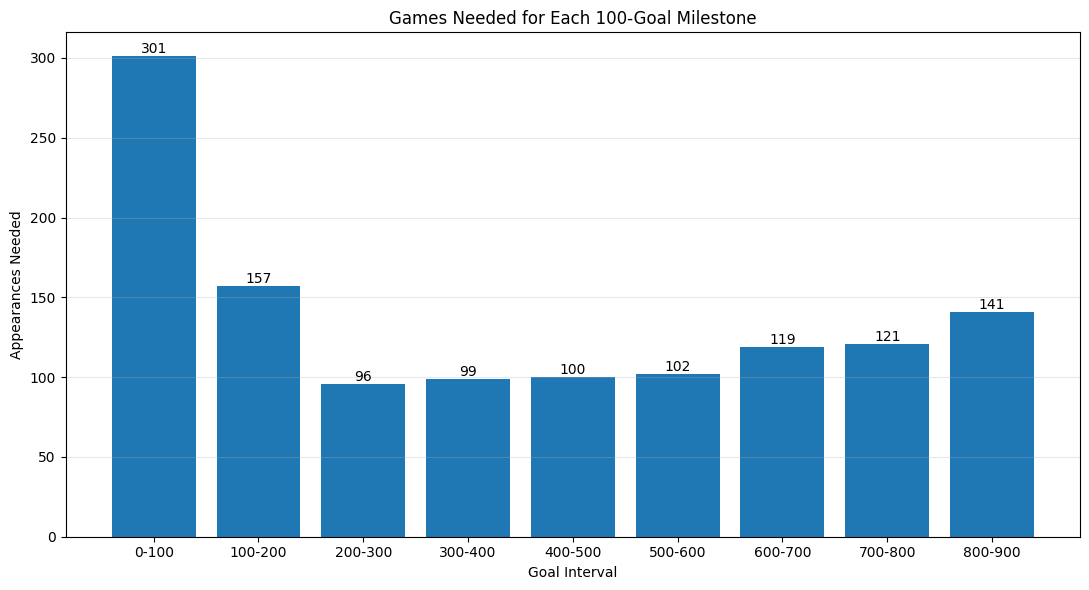

,milestone,games
0,0-100,301
1,100-200,157
2,200-300,96
3,300-400,99
4,400-500,100
5,500-600,102
6,600-700,119
7,700-800,121
8,800-900,141


In [20]:
# Games Needed for Each 100-Goal Milestone

milestone_df = matches_df.copy()
milestone_df["goals"] = milestone_df["goals"].fillna(0)

milestone_df["cumulative_goals"] = milestone_df["goals"].cumsum()
milestone_df["appearance_number"] = np.arange(
    1, len(milestone_df) + 1
)

milestones = list(range(100, 901, 100))
milestone_results = []
previous_appearance = 0
previous_goal_total = 0

for milestone in milestones:
    reached = milestone_df[
        milestone_df["cumulative_goals"] >= milestone
    ]

    if reached.empty:
        break

    appearance_at_milestone = int(
        reached.iloc[0]["appearance_number"]
    )

    games_needed = appearance_at_milestone - previous_appearance

    milestone_results.append({
        "milestone": f"{previous_goal_total}-{milestone}",
        "games": games_needed
    })

    previous_appearance = appearance_at_milestone
    previous_goal_total = milestone

milestone_stats = pd.DataFrame(milestone_results)

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    milestone_stats["milestone"],
    milestone_stats["games"]
)

ax.set_title("Games Needed for Each 100-Goal Milestone")
ax.set_xlabel("Goal Interval")
ax.set_ylabel("Appearances Needed")
ax.grid(axis="y", alpha=0.3)

for i, value in enumerate(milestone_stats["games"]):
    ax.text(i, value, str(value), ha="center", va="bottom")

fig.tight_layout()
fig.savefig(
    output_dir / "ronaldo-games-per-100-goals.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

display(milestone_stats)

### Visualization 3: Scoring Output Distribution

The following graph shows two lines depicting Cristiano Ronaldo's scoring rate per appearance and per 90 minutes. Overall, the two lines are very close, showing minimal difference. His scoring rate first was lower until the 2006/07 season, when it shot up from about 0.3 to 0.5, then shot up again the following season to 0.8 goals per game. In 2008/09, it dropped down, but went right up the following season and remained at that level or higher until the end of the 2017/18 season, which encapsulated his Real Madrid career. Since then, two instances occured where his scoring rate shot up (2019/20 and 2023/24) before slowly declining one season at a time.

The per 90 line is slightly lower due to its accuracy. Since football matches are 90 minutes long, the per 90 calculation is more accurate and lower. Given the previous equation for per 90, the per appearance calculation differs because it multiplies the quotient by 90. The only significant gap in lines comes at the start of his career, which can be attributed to the fact that he was a rotation player when he was younger, coming on or being substituted off, not playing the full 90 minutes.

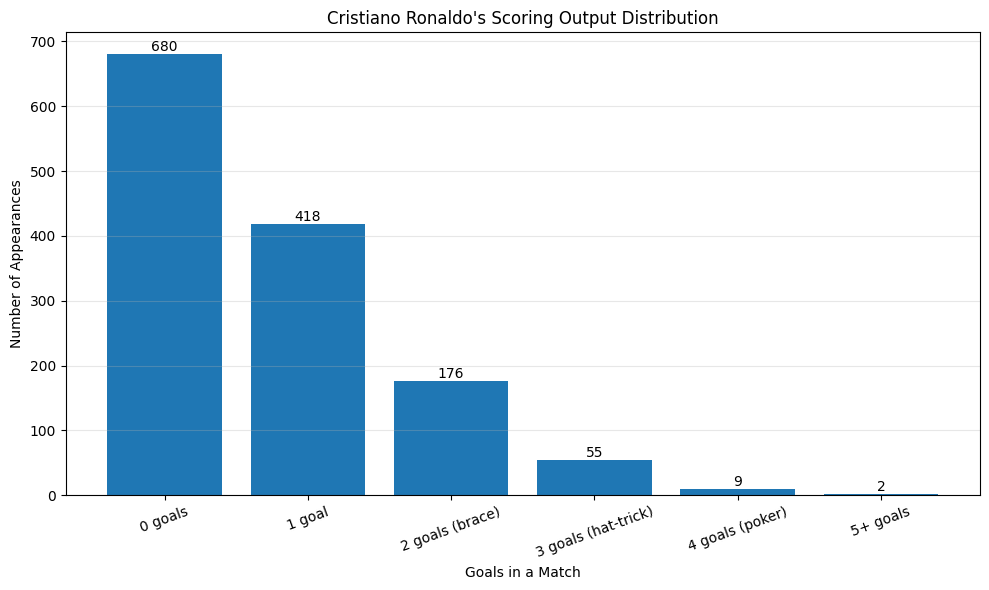

,appearances
goals,
0 goals,680
1 goal,418
2 goals (brace),176
3 goals (hat-trick),55
4 goals (poker),9
5+ goals,2


In [21]:
# Scoring Output Distribution

goals_per_match = matches_df["goals"].fillna(0)

def classify_goals(goals):
    if goals == 0:
        return "0 goals"
    elif goals == 1:
        return "1 goal"
    elif goals == 2:
        return "2 goals (brace)"
    elif goals == 3:
        return "3 goals (hat-trick)"
    elif goals == 4:
        return "4 goals (poker)"
    else:
        return "5+ goals"

distribution_order = [
    "0 goals",
    "1 goal",
    "2 goals (brace)",
    "3 goals (hat-trick)",
    "4 goals (poker)",
    "5+ goals"
]

distribution = (
    goals_per_match.apply(classify_goals)
    .value_counts()
    .reindex(distribution_order, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(distribution.index, distribution.values)

ax.set_title("Cristiano Ronaldo's Scoring Output Distribution")
ax.set_xlabel("Goals in a Match")
ax.set_ylabel("Number of Appearances")
ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", alpha=0.3)

for i, value in enumerate(distribution.values):
    ax.text(i, value, str(value), ha="center", va="bottom")

fig.tight_layout()
fig.savefig(
    output_dir / "ronaldo-scoring-output-distribution.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

display(
    distribution.rename("appearances").to_frame()
)

### Visualization 4: Scoring Rate by Competition

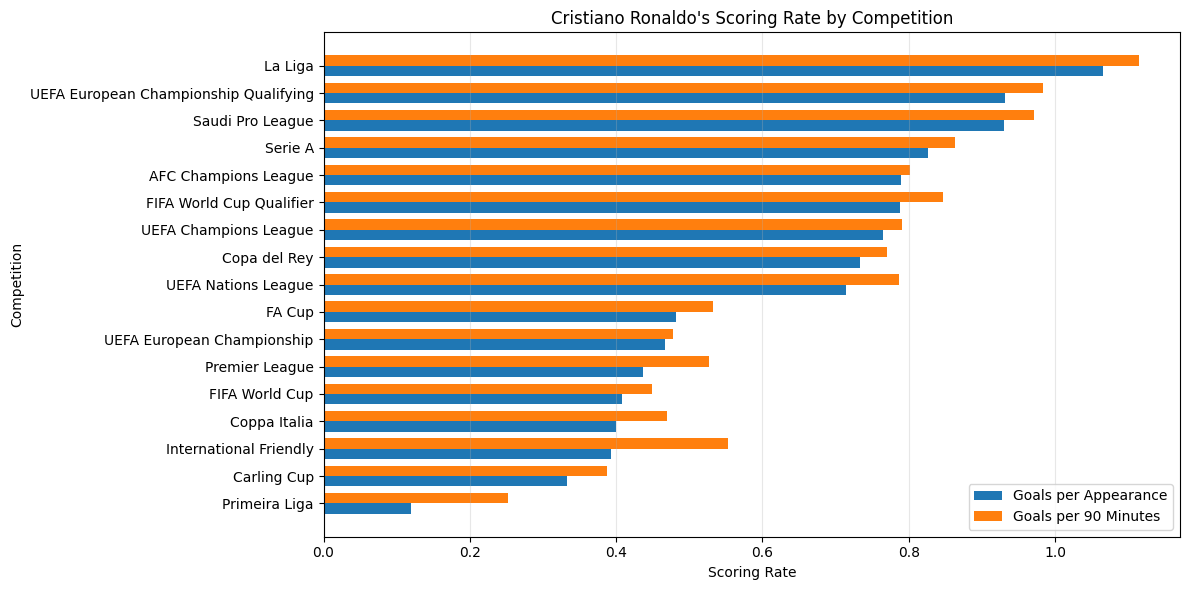

,appearances,goals,minutes,goals_per_appearance,goals_per_90
competition,,,,,
Primeira Liga,25,3,1069,0.120,0.253
Carling Cup,12,4,930,0.333,0.387
International Friendly,56,22,3578,0.393,0.553
Coppa Italia,10,4,766,0.400,0.470
FIFA World Cup,27,11,2203,0.407,0.449
Premier League,236,103,17609,0.436,0.526
UEFA European Championship,30,14,2640,0.467,0.477
FA Cup,27,13,2196,0.481,0.533
UEFA Nations League,21,15,1717,0.714,0.786


In [22]:
# Goal-Scoring Rate by Competition

if "competition" not in matches_df.columns:
    raise ValueError(
        "The match data has no 'competition' column. "
        "Check the JSON field names."
    )

competition_stats = (
    matches_df.dropna(subset=["competition"])
    .groupby("competition")
    .agg(
        appearances=("date", "size"),
        goals=("goals", "sum"),
        minutes=("minutesPlayed", "sum")
    )
)

competition_stats["goals_per_appearance"] = (
    competition_stats["goals"] / competition_stats["appearances"]
)

competition_stats["goals_per_90"] = (
    competition_stats["goals"] / competition_stats["minutes"] * 90
)

competition_stats = competition_stats[
    competition_stats["appearances"] >= 10
].sort_values("goals_per_appearance", ascending=True)

fig, ax = plt.subplots(figsize=(12, max(6, len(competition_stats) * 0.35)))

y = np.arange(len(competition_stats))
bar_height = 0.38

ax.barh(
    y - bar_height / 2,
    competition_stats["goals_per_appearance"],
    height=bar_height,
    label="Goals per Appearance"
)

ax.barh(
    y + bar_height / 2,
    competition_stats["goals_per_90"],
    height=bar_height,
    label="Goals per 90 Minutes"
)

ax.set_yticks(y)
ax.set_yticklabels(competition_stats.index)
ax.set_title("Cristiano Ronaldo's Scoring Rate by Competition")
ax.set_xlabel("Scoring Rate")
ax.set_ylabel("Competition")
ax.grid(axis="x", alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    output_dir / "ronaldo-scoring-rate-by-competition.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

display(competition_stats.round(3))

### Visualization 5: Injury / Absence Hypothetical

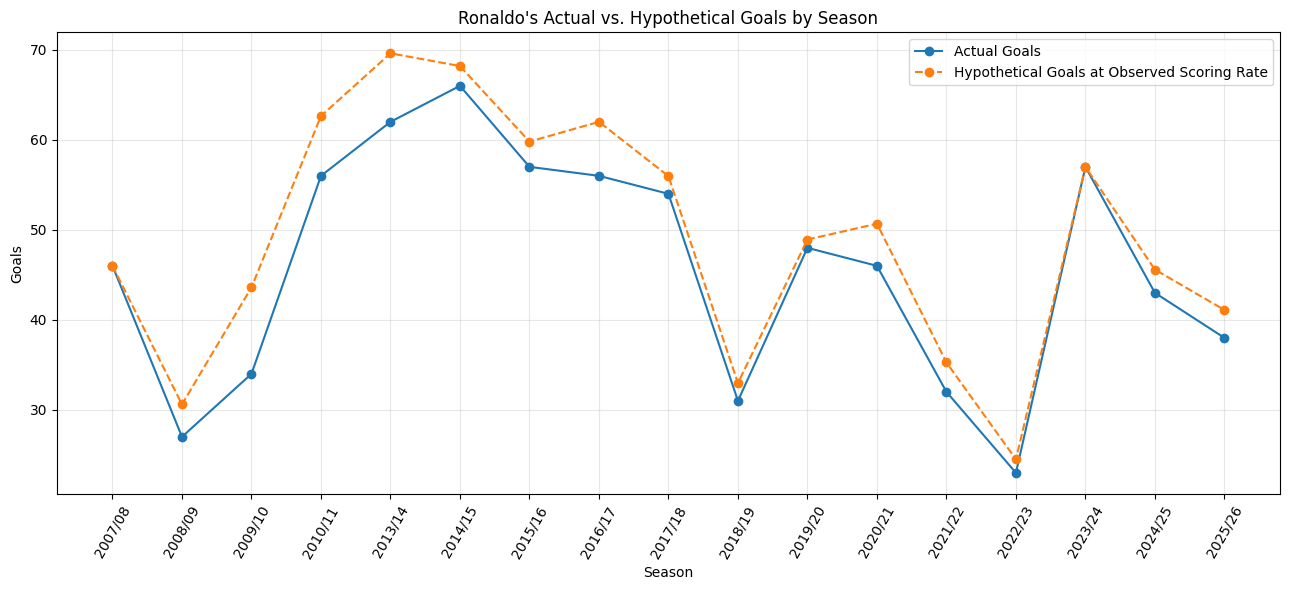

,season,appearances,goals,goals_per_appearance,games_missed,hypothetical_extra_goals,hypothetical_goals
5,2007/08,61,46,0.75,0.0,0.00,46.00
6,2008/09,60,27,0.45,8.0,3.60,30.60
7,2009/10,46,34,0.74,13.0,9.61,43.61
8,2010/11,59,56,0.95,7.0,6.64,62.64
11,2013/14,57,62,1.09,7.0,7.61,69.61
12,2014/15,60,66,1.10,2.0,2.20,68.20
13,2015/16,61,57,0.93,3.0,2.80,59.80
14,2016/17,56,56,1.00,6.0,6.00,62.00
15,2017/18,55,54,0.98,2.0,1.96,55.96
16,2018/19,47,31,0.66,3.0,1.98,32.98


In [23]:
# 5. Injury / Absence Hypothetical

injury_data = [
    {"season": "25/26", "days_missed": 33, "injuries": 1, "games_missed": 4},
    {"season": "24/25", "days_missed": 30, "injuries": 3, "games_missed": 3},
    {"season": "23/24", "days_missed": 20, "injuries": 1, "games_missed": 0},
    {"season": "22/23", "days_missed": 10, "injuries": 1, "games_missed": 3},
    {"season": "21/22", "days_missed": 23, "injuries": 4, "games_missed": 5},
    {"season": "20/21", "days_missed": 23, "injuries": 2, "games_missed": 6},
    {"season": "19/20", "days_missed": 4,  "injuries": 1, "games_missed": 1},
    {"season": "18/19", "days_missed": 15, "injuries": 1, "games_missed": 3},
    {"season": "17/18", "days_missed": 8,  "injuries": 1, "games_missed": 2},
    {"season": "16/17", "days_missed": 70, "injuries": 3, "games_missed": 6},
    {"season": "15/16", "days_missed": 12, "injuries": 1, "games_missed": 3},
    {"season": "14/15", "days_missed": 18, "injuries": 1, "games_missed": 2},
    {"season": "13/14", "days_missed": 42, "injuries": 3, "games_missed": 7},
    {"season": "10/11", "days_missed": 38, "injuries": 3, "games_missed": 7},
    {"season": "09/10", "days_missed": 51, "injuries": 2, "games_missed": 13},
    {"season": "08/09", "days_missed": 71, "injuries": 1, "games_missed": 8},
    {"season": "07/08", "days_missed": 47, "injuries": 1, "games_missed": 0},
]

injury_df = pd.DataFrame(injury_data)

def normalize_season_label(label):
    label = str(label).strip()
    if len(label) == 5 and label[2] == "/":
        start = int(label[:2])
        century = "20" if start < 50 else "19"
        return century + label[:2] + "/" + label[3:]
    return label

injury_df["season"] = injury_df["season"].apply(
    normalize_season_label
)

actual_stats = season_stats_all.copy()
actual_stats["season"] = actual_stats["season"].astype(str)

injury_comparison = actual_stats.merge(
    injury_df[["season", "games_missed"]],
    on="season",
    how="left"
)

injury_comparison["hypothetical_extra_goals"] = (
    injury_comparison["goals_per_appearance"]
    * injury_comparison["games_missed"]
)

injury_comparison["hypothetical_goals"] = (
    injury_comparison["goals"]
    + injury_comparison["hypothetical_extra_goals"]
)

injury_comparison["hypothetical_goals"] = (
    injury_comparison["hypothetical_goals"].where(
        injury_comparison["games_missed"].notna()
    )
)

injury_plot = injury_comparison.dropna(
    subset=["games_missed", "goals", "hypothetical_goals"]
).copy()

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    injury_plot["season"],
    injury_plot["goals"],
    marker="o",
    label="Actual Goals"
)

ax.plot(
    injury_plot["season"],
    injury_plot["hypothetical_goals"],
    marker="o",
    linestyle="--",
    label="Hypothetical Goals at Observed Scoring Rate"
)

ax.set_title("Ronaldo's Actual vs. Hypothetical Goals by Season")
ax.set_xlabel("Season")
ax.set_ylabel("Goals")
ax.tick_params(axis="x", rotation=60)
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    output_dir / "ronaldo-injury-hypothetical.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

display(
    injury_plot[
        [
            "season", "appearances", "goals",
            "goals_per_appearance", "games_missed",
            "hypothetical_extra_goals", "hypothetical_goals"
        ]
    ].round(2)
)

### Visualization 6: Overall Career Time Series

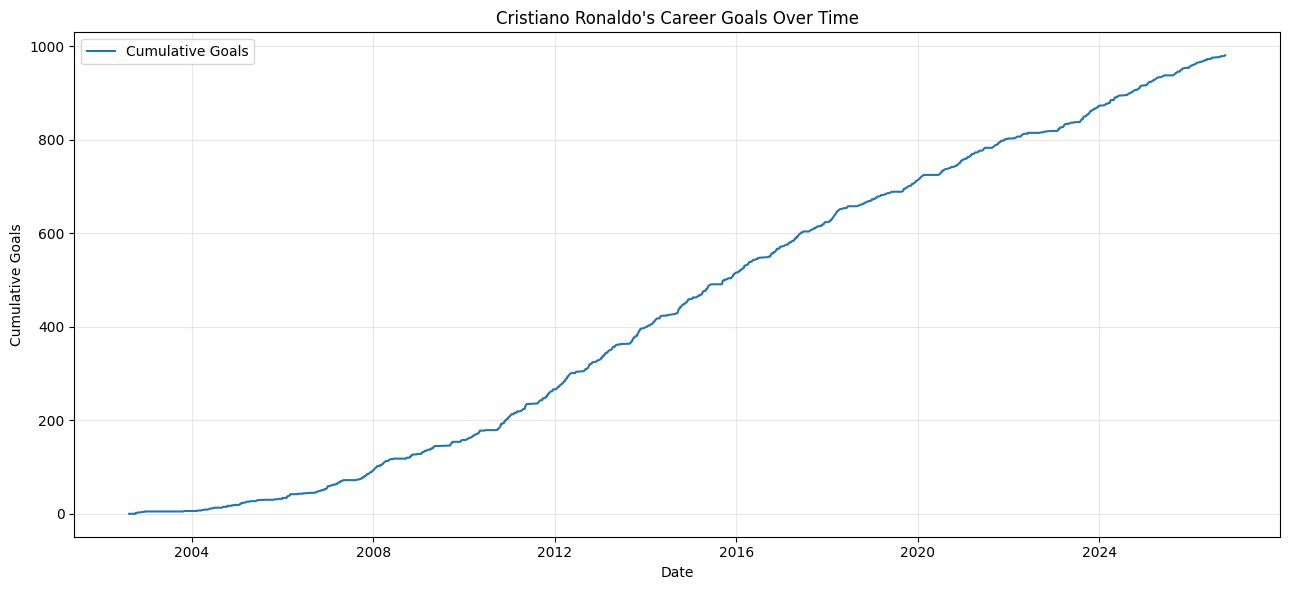

In [24]:
# Overall Career Time Series

career_series = matches_df.copy()

career_series["cumulative_goals"] = (
    career_series["goals"].fillna(0).cumsum()
)

career_series["cumulative_appearances"] = np.arange(
    1, len(career_series) + 1
)

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    career_series["date"],
    career_series["cumulative_goals"],
    label="Cumulative Goals"
)

ax.set_title("Cristiano Ronaldo's Career Goals Over Time")
ax.set_xlabel("Date")
ax.set_ylabel("Cumulative Goals")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    output_dir / "ronaldo-career-time-series.png",
    dpi=200, bbox_inches="tight"
)
plt.show()
